# Airbnb: clean, split, train, cross-validate, test

**A 20-minute classroom demo.** We will predict whether a Sydney Airbnb listing costs **at least $300 per night**. This is a binary classification task, not a prediction of the exact price.

- **Training (60%):** practice questions; learn cleaning rules and model patterns.
- **Validation (20%):** a mock exam; choose between two simple models.
- **Cross-validation inside training:** rotate five practice groups to see how scores vary across splits.
- **Test (20%):** the final exam; evaluate the chosen model once.

**Stratification** keeps approximately the same proportion of each price class in all three sets. **Data leakage** means letting information from the exam influence learning. We will avoid it with a pipeline.

Data: Inside Airbnb, Sydney snapshot 16 June 2026, CC BY 4.0; supplied in `data/sydney_airbnb.csv`. Use the same Python environment as the other course notebooks, then **Run All**. No downloads are needed.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
PRICE_THRESHOLD = 300
USE_STRATIFICATION=True # Default to True. For the exercise variant set to False

# To help convert styled tables to LaTeX with the right setup for nbconvert
def style_latex_table(styler):
    """Style LaTeX tables; requires colortbl in the PDF template."""
    def stripe_rows(values):
        return [
            # Wrap the content directly to avoid a leading space after cellcolor.
            "cellcolor:{gray!10}--rwrap;" if i % 2 == 0 else ""
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + "bfseries:;" for style in stripe_rows(values)]

    return (
        styler
        .format_index(escape="latex", axis=0)  # Escape row labels.
        .format_index(escape="latex", axis=1)  # Escape column headers.
        .apply(stripe_rows, axis=0)
        .apply_index(style_index, axis=0)
        .map_index(lambda value: "bfseries:;", axis=1)
    )

## 1. Load a small selection of columns

Each row is a listing. We use only five easy-to-explain inputs. `price` creates the answer; `id` identifies duplicate listings. **Neither will be an input to the model.** Revenue is also excluded because it may be calculated using price.

In [2]:
data_path = Path('data') / 'sydney_airbnb.csv'
if not data_path.is_file():
    data_path = (Path('IATD-Machine-Learning-Algorithms')
                 / 'IATD-Machine-Learning-Algorithms' / 'data' / 'sydney_airbnb.csv')
if not data_path.is_file():
    raise FileNotFoundError('Open this notebook from the course folder or MachineLearning workspace.')

numeric_columns = ['accommodates', 'bedrooms', 'bathrooms']
categorical_columns = ['suburb', 'room_type']
feature_columns = numeric_columns + categorical_columns
raw = pd.read_csv(data_path, usecols=['id', 'price'] + feature_columns)
print(f'Loaded {len(raw):,} listings')
display(raw.head())
display(raw.isna().sum().rename('Missing values before cleaning').to_frame())

Loaded 20,573 listings


,id,suburb,room_type,accommodates,bathrooms,bedrooms,price
0,11156,Sydney,Private room,1,NaN,NaN,24.7
1,15253,Sydney,Private room,2,1.0,NaN,144.7
2,44545,Sydney,Entire home/apt,2,NaN,1.0,NaN
3,58506,Mosman,Entire home/apt,4,1.0,1.0,240.0
4,1141803,Sydney,Entire home/apt,2,1.0,1.0,456.5


,Missing values before cleaning
id,0
suburb,0
room_type,0
accommodates,0
bathrooms,5724
bedrooms,3107
price,2787


## 2. Clean fixed data-quality problems

We remove repeated listing IDs, standardise whitespace, and turn invalid numbers into missing values. Zero bedrooms can mean a studio, so it is allowed. A listing must have a known, positive price to provide a trustworthy answer.

**Do not fill missing inputs yet.** Fixed rules can be applied before splitting because they do not learn averages or patterns. Median values and category encodings must be learned from training data only. The report shows actual changes; some counts may be zero.

In [3]:
# test what will happen if we coerce a price
test_coerce_bool = False

if test_coerce_bool:
    print("WARNING: Coercing a price (and other variables) for something that doesn't make sense for testing. Don't forget to set test_coerce_bool=False before running the rest of the notebook.")
    raw['price'] = df['price'].astype(object)
    raw.loc[raw.index[2], 'price'] = 'not-a-number'

    raw.loc[raw.index[2], 'suburb'] = '' # Empty string
    raw.loc[raw.index[2], 'bedrooms'] = -1 # Negative (impossible) number of bedrooms

# Keep the first row for each unique listing ID, then make an independent
# copy so we can clean df without changing raw. This replaces any existing df.
df = raw.drop_duplicates(subset='id').copy()
duplicates_removed = len(raw) - len(df)

coerced_values = pd.DataFrame(index=df.index)

for column in ['price'] + numeric_columns:
    #df[column] = pd.to_numeric(df[column], errors='coerce')
    original = df[column]
    converted = pd.to_numeric(original, errors='coerce')

    #coerced = original.notna() & converted.isna()
    #print(f"{column}: {coerced.sum()} values coerced to NaN")
    coerced_values[column] = original.notna() & converted.isna()

    df[column] = converted

#display(coerced_values.sum().to_frame('Values coerced to NaN'))

df[['price'] + numeric_columns] = df[['price'] + numeric_columns].replace([np.inf, -np.inf], np.nan)

invalid_features = pd.DataFrame({
    'accommodates': df['accommodates'] <= 0,
    'bedrooms': df['bedrooms'] < 0, # It is less than zero, instead of less than or equal to zero as the number of bedroom can actually be zero in the case of a studio.
    'bathrooms': df['bathrooms'] <= 0,
})

columns_that_will_be_changed = numeric_columns + categorical_columns
missing_before = df[columns_that_will_be_changed].isna().sum()

# Replace numeric values with NaN wherever invalid_features is True.
df[numeric_columns] = df[numeric_columns].mask(invalid_features)

for column in categorical_columns:
    # Remove leading and trailing whitespace, then replace empty strings
    # (including those that contained only whitespace) with NaN.
    df[column] = df[column].str.strip().replace('', np.nan)

replaced = df[columns_that_will_be_changed].isna().sum() - missing_before
#display(replaced.to_frame('Values replaced with NaN'))


missing_or_invalid_price = df['price'].isna() | (df['price'] <= 0)
unlabelled_removed = int(missing_or_invalid_price.sum())
df = df.loc[~missing_or_invalid_price].copy()
df['high_price'] = (df['price'] >= PRICE_THRESHOLD).astype(int)

display(pd.Series({
    'Duplicate listing rows removed': duplicates_removed,
    'Missing/nonpositive price rows removed': unlabelled_removed,
    'Invalid input values marked missing': int(invalid_features.sum().sum()),
    'Labelled rows remaining': len(df),
}).to_frame('Count'))
#display(df[feature_columns].isna().sum().to_frame('Missing inputs still to fill'))

cleaning_report = pd.concat([
    coerced_values.sum().rename('Numeric values coerced to NaN'),
    replaced.rename('Values replaced with NaN'),
    df[feature_columns].isna().sum().rename('Missing inputs still to fill')
], axis=1)

styled_report = style_latex_table(
    cleaning_report.style.format('{:.0f}', na_rep='—')
)

#display(styled_report)
display({
    "text/html": cleaning_report.style.format(
        "{:.0f}", na_rep="—"
    ).to_html(),
    "text/latex": style_latex_table(
        cleaning_report.style.format("{:.0f}", na_rep="—")
    ).to_latex(
        column_format=(
            r"r"
            r">{\raggedright\arraybackslash}p{3.5cm}"
            r">{\raggedright\arraybackslash}p{3.5cm}"
            r">{\raggedright\arraybackslash}p{3.5cm}"
        ),
    ),
}, raw=True)

#display(df['high_price'].value_counts().sort_index().rename_axis('Class').to_frame('Listings'))
class_counts = (
    df['high_price'].value_counts().sort_index()
    .rename_axis('Class').to_frame('Listings')
)

class_counts['Percentage'] = class_counts['Listings'] / class_counts['Listings'].sum()

'''display(
    style_latex_table(
        class_counts.reset_index().style
        .hide(axis='index')
        .format({
            'Listings': '{:,}',
            'Percentage': '{:.1%}',
        })
    )
)'''
table = class_counts.reset_index()

display({
    "text/html": table.style.hide(axis="index").format({
        "Listings": "{:,}",
        "Percentage": "{:.1%}",
    }).to_html(),
    "text/latex": style_latex_table(
        table.style.hide(axis="index").format({
            "Listings": "{:,}",
            "Percentage": lambda x: f"{x:.1%}".replace("%", r"\%"),
        })
    ).to_latex(),
}, raw=True)

#print('Class 0: price < $300; class 1: price >= $300. Threshold fixed for teaching, not learned from the data.')
display(Markdown(r"""
**Price classes**

- **Class 0:** price < \$300
- **Class 1:** price ≥ \$300

**Threshold fixed for teaching**, not learned from the data.
"""))

,Count
Duplicate listing rows removed,0
Missing/nonpositive price rows removed,2787
Invalid input values marked missing,0
Labelled rows remaining,17786


,Numeric values coerced to NaN,Values replaced with NaN,Missing inputs still to fill
price,0,—,—
accommodates,0,0,0
bedrooms,0,0,2727
bathrooms,0,0,3022
suburb,—,0,0
room_type,—,0,0


Class,Listings,Percentage
0,"9,207",51.8%
1,"8,579",48.2%



**Price classes**

- **Class 0:** price < \$300
- **Class 1:** price ≥ \$300

**Threshold fixed for teaching**, not learned from the data.


## 3. Make a stratified 60 / 20 / 20 split

First keep **60% for training** and hold out 40%. Then split the held-out portion in half: **20% validation + 20% test** of the original labelled data.

`stratify=y` preserves class proportions; it does not balance them to 50/50. The second split must stratify using **the held-out labels**, not the full labels. `random_state` makes the example reproducible.

It is normal to use labels for stratification. Do not use test predictions or scores to choose a model.

### Understanding stratification and reproducibility

We split the data into **60% training**, **20% validation**, and **20% test** in two steps:

1. Set aside **60% for training**, holding out the remaining **40%**.
2. Split that held-out portion equally into **validation** and **test** sets.

**`stratify=y` preserves class proportions.** It tells `train_test_split` to use the labels in `y` when dividing the rows. For example, if the original data contains 70% class 0 and 30% class 1, each split will contain approximately those proportions. Stratification does **not** balance the classes to 50/50.

**For the non-stratified exercise variant, use `stratify=None` in both split calls.** With the default `shuffle=True`, rows are randomly divided without explicitly preserving class proportions. The proportions may still be similar by chance.

| Variant | First split | Second split |
|---|---|---|
| Stratified | `stratify=y` | `stratify=y_holdout` |
| Non-stratified | `stratify=None` | `stratify=None` |

`None` is also the default if `stratify` is omitted. Use the Python value `None`, not the string `'None'` or `False`.

Keep `random_state` fixed to make either variant reproducible. If you set `shuffle=False`, `stratify` must be `None`.

See the [official train_test_split documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

**If stratification is enabled, the second split uses `stratify=y_holdout`.** We are splitting only the held-out rows, so stratification requires their corresponding labels, in the same row order—not the labels for the full dataset.

**For the non-stratified variant, use `stratify=None` instead.** We still pass `y_holdout` as the labels to split alongside `X_holdout`, but do not use them to preserve class proportions.

**`random_state=42` makes the split reproducible.** Running the code again with the same data in the same order produces the same split. The number `42` is arbitrary; using a fixed value is what matters.

,Rows,Share of data (%),Class 0 (%),Class 1 (%)
Set,,,,
All labelled data,17786,100.0,51.77,48.23
Training,10671,60.0,51.77,48.23
Validation,3557,20.0,51.76,48.24
Test,3558,20.0,51.77,48.23


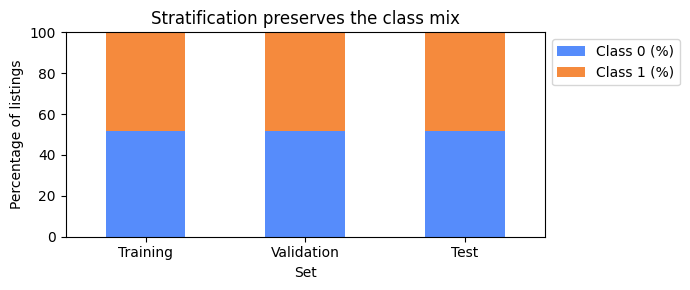

In [4]:
X = df[feature_columns]
y = df['high_price']

if USE_STRATIFICATION:
    pass
else:
    print("WARNING: you're doing the exercise variant where data is not stratified.")
    stratify=None

# Keep 60% for training; hold out 40%.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.40, stratify=y if USE_STRATIFICATION else None, random_state=SEED
)
# Split the held-out 40% in half: 20% validation and 20% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, stratify=y_holdout if USE_STRATIFICATION else None, random_state=SEED
)

# Check that training and validation share no row indexes.
assert set(X_train.index).isdisjoint(X_val.index)

# Check that training and test share no row indexes.
assert set(X_train.index).isdisjoint(X_test.index)

# Check that validation and test share no row indexes.
assert set(X_val.index).isdisjoint(X_test.index)

# Check that the three sets together contain all original row indexes,
# with none missing or added. The | operator combines sets (union).
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(X.index)

split_summary = pd.DataFrame([
    {'Set': name, 'Rows': len(labels), 'Share of data (%)': 100 * len(labels) / len(y),
     'Class 0 (%)': 100 * (1 - labels.mean()), 'Class 1 (%)': 100 * labels.mean()}
    for name, labels in [('All labelled data', y), ('Training', y_train),
                         ('Validation', y_val), ('Test', y_test)]
]).set_index('Set')
display(split_summary.round(2))

if USE_STRATIFICATION:
    for labels in [y_train, y_val, y_test]:
        assert abs(labels.mean() - y.mean()) < 0.002

split_summary.loc[['Training', 'Validation', 'Test'], ['Class 0 (%)', 'Class 1 (%)']].plot.bar(
    stacked=True, figsize=(7, 3), rot=0, ylim=(0, 100), ylabel='Percentage of listings',
    title='Stratification preserves the class mix'
)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 4. Put learned cleaning and the model in one pipeline

- **Numeric inputs:** fill missing values with the training median.
- **Categorical inputs:** fill gaps with the training most-frequent category, then one-hot encode (make category indicator columns).
- **Unknown categories:** `handle_unknown='ignore'` lets a new suburb be processed without an error.
- **Decision tree:** learn simple questions such as 'bedrooms > 2?'. `max_depth` limits how many levels of questions it can ask. Trees do not require scaling.

`fit(X_train, y_train)` learns both preprocessing and the tree. `predict(X_val)` reuses those rules; it does **not** recalculate medians on validation data.

In [5]:
display(Markdown(f"""
**Columns that will be preprocessed**

- **Numerical columns:** {', '.join(f'`{col}`' for col in numeric_columns)}
- **Categorical columns:** {', '.join(f'`{col}`' for col in categorical_columns)}
"""))

def make_model(depth, random_state=SEED):
    """
    Build an unfitted preprocessing and decision-tree classification pipeline.

    Missing numerical values are filled with each column's median.
    Missing categorical values are filled with the most frequent category,
    then one-hot encoded. Unseen categories are ignored during encoding.

    Parameters
    ----------
    depth : int or None
        Maximum depth of the decision tree. Use a positive integer to limit
        depth, or None to allow growth until other stopping criteria apply.

    random_state : int or None, optional
        Random seed for the decision tree. Defaults to SEED.
        Use an integer for reproducible results, or None for randomness
        without a fixed seed.

    Returns
    -------
    sklearn.pipeline.Pipeline
        A pipeline containing preprocessing and a decision-tree classifier
        with a fixed random seed.

    Notes
    -----
    Preprocessing statistics and categories are learned only when fit()
    is called. Fit on training data to avoid data leakage.
    """

    # Apply different preprocessing to numerical and categorical columns,
    # then combine their outputs into one feature matrix.
    # Each tuple contains: (name, transformer, columns).
    preprocessing = ColumnTransformer([
        # 'numbers' names this transformer so we can retrieve it after fitting.
        # Fill missing numerical values with each column's median,
        # learned from the data passed to fit().
        ('numbers', SimpleImputer(strategy='median'), numeric_columns),

        # 'categories' applies two steps in sequence to categorical columns.
        ('categories', Pipeline([
            # Fill missing values with each column's most frequent category,
            # learned during fit().
            ('fill', SimpleImputer(strategy='most_frequent')),

            # Create binary indicator columns for the categories learned during fit().
            # Unseen categories during prediction produce all zeros for that feature.
            ('encode', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical_columns),
    ])

    return Pipeline([
        ('clean', preprocessing),
        ('model', DecisionTreeClassifier(max_depth=depth, random_state=random_state)),
    ])


**Columns that will be preprocessed**

- **Numerical columns:** `accommodates`, `bedrooms`, `bathrooms`
- **Categorical columns:** `suburb`, `room_type`


## 5. Train on training data; choose using validation data

Compare two depths, 3 and 5. A deeper tree can learn more detail, but can also memorise noise (**overfit**).

**Accuracy** is the fraction of correct answers. **Balanced accuracy** averages recall across the two classes, giving each class equal weight. We choose the higher validation balanced accuracy, keeping the shallower tree if tied.

A **baseline** always guesses the most common training class. A model should improve on this simple reference. Do not open the test results yet.

### Understanding the evaluation metrics

We treat **class 1 (price ≥ $300)** as the positive class:

- **True positive (TP):** correctly predicted class 1.
- **True negative (TN):** correctly predicted class 0.
- **False positive (FP):** predicted class 1, but the actual class was 0.
- **False negative (FN):** predicted class 0, but the actual class was 1.

**Accuracy** is the fraction of all predictions that are correct:

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Recall** measures the fraction of a class's actual listings that the model correctly identifies:

$$
\text{Recall}_1 = \frac{TP}{TP + FN}
\qquad
\text{Recall}_0 = \frac{TN}{TN + FP}
$$

**Balanced accuracy** averages recall across the two classes, giving each class equal weight regardless of how many listings it contains:

$$
\text{Balanced accuracy}
= \frac{\text{Recall}_0 + \text{Recall}_1}{2}
= \frac{1}{2}\left(
\frac{TN}{TN + FP} + \frac{TP}{TP + FN}
\right)
$$

For example, if 70% of listings belong to class 0, always predicting class 0 gives **70% accuracy** but only **50% balanced accuracy**: recall is 100% for class 0 and 0% for class 1.

### Choosing a model

We choose the model with the **higher validation balanced accuracy**, keeping the **shallower tree if tied**.

A **baseline** always guesses the most common training class. A model should improve on this simple reference.

**Do not open the test results yet.** Use validation results to choose the model, then evaluate the chosen model on the test set.

In [6]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_val = baseline.predict(X_val)
print(f'Baseline validation accuracy: {accuracy_score(y_val, baseline_val):.3f}')
print(f'Baseline validation balanced accuracy: {balanced_accuracy_score(y_val, baseline_val):.3f}')

models = {}
results = []
# Compare several maximum tree depths.
# Dipanjan used 3 and 5; I also try 1, 2 and 50
for depth in [1, 2, 3, 5, 50]:
    # Create a fresh preprocessing pipeline and decision tree.
    model = make_model(depth)
    # Learn preprocessing values and tree rules from training data only.
    model.fit(X_train, y_train)
    # Save the fitted pipeline so we can retrieve the winner later.
    models[depth] = model
    # Measure performance on the data used for training.
    train_predictions = model.predict(X_train)
    # Predict validation labels using the fitted pipeline, without refitting.
    val_predictions = model.predict(X_val)
    # Record scores for comparison.
    # Training versus validation accuracy helps reveal overfitting.
    # Validation balanced accuracy will be used later to choose the best depth.
    results.append({
        'Depth': depth,
        'Training accuracy': accuracy_score(y_train, train_predictions),
        'Validation accuracy': accuracy_score(y_val, val_predictions),
        'Validation balanced accuracy': balanced_accuracy_score(y_val, val_predictions),
    })

validation_results = pd.DataFrame(results).set_index('Depth')
#display(validation_results.round(3))
'''display(
    style_latex_table(
        validation_results.rename_axis('Depth').reset_index().style
        .hide(axis='index').
        format(precision=3)
    )
)'''
table = validation_results.rename_axis('Depth').reset_index()

display({
    "text/html": table.style
        .hide(axis="index")
        .format(precision=3)
        .to_html(),
    "text/latex": style_latex_table(
        table.style
        .hide(axis="index")
        .format(precision=3)
    ).to_latex(),
}, raw=True)

best_depth = validation_results['Validation balanced accuracy'].idxmax()
best_model = models[best_depth]
print(f'Chosen depth: {best_depth}. The test set has not been used for model selection.')

DEBUG = True

if DEBUG:
    display(Markdown('**Debug lines to show the before and after the preprocessing**'))
    # Select a few validation rows before preprocessing.
    sample = X_val.iloc[3:8]
    preprocessing = best_model.named_steps['clean']

    # Apply the already-learned rules without fitting again.
    transformed = preprocessing.transform(sample)

    # Convert sparse output to a dense array for this small preview.
    if hasattr(transformed, 'toarray'):
        transformed = transformed.toarray()

    # Attach the generated column names and preserve the original row indexes.
    after = pd.DataFrame(
        transformed,
        columns=preprocessing.get_feature_names_out(),
        index=sample.index,
    )

    # Keep all numerical columns.
    preview_columns = [
        col for col in after.columns
        if col.startswith('numbers__')
    ]

    # Keep only the first two encoded columns per categorical feature.
    for column in categorical_columns:
        encoded_columns = [
            col for col in after.columns
            if col.startswith(f'categories__{column}_')
        ]
        preview_columns.extend(encoded_columns[:2])

    display(Markdown('**Before preprocessing**'))
    display(sample)

    #display(Markdown('**After preprocessing**'))
    #display(after)
    display(Markdown('**After preprocessing — selected columns**'))
    display(after[preview_columns])

Baseline validation accuracy: 0.518
Baseline validation balanced accuracy: 0.500


Depth,Training accuracy,Validation accuracy,Validation balanced accuracy
1,0.771,0.771,0.773
2,0.771,0.771,0.773
3,0.783,0.780,0.780
5,0.791,0.781,0.781
50,0.828,0.782,0.780


Chosen depth: 5. The test set has not been used for model selection.


**Debug lines to show the before and after the preprocessing**

**Before preprocessing**

,accommodates,bedrooms,bathrooms,suburb,room_type
5115,4,2.0,1.0,Ashfield,Entire home/apt
12040,8,3.0,NaN,North Sydney,Entire home/apt
19716,3,1.0,1.0,Sydney,Entire home/apt
17601,5,4.0,3.0,Willoughby,Entire home/apt
3678,2,NaN,NaN,Parramatta,Private room


**After preprocessing — selected columns**

,numbers__accommodates,numbers__bedrooms,numbers__bathrooms,categories__suburb_Ashfield,categories__suburb_Auburn,categories__room_type_Entire home/apt,categories__room_type_Hotel room
5115,4.0,2.0,1.0,1.0,0.0,1.0,0.0
12040,8.0,3.0,1.0,0.0,0.0,1.0,0.0
19716,3.0,1.0,1.0,0.0,0.0,1.0,0.0
17601,5.0,4.0,3.0,0.0,0.0,1.0,0.0
3678,2.0,2.0,1.0,0.0,0.0,0.0,0.0


### Check: where did the filling values come from?

The learned imputer values must equal the **training medians**. Missing inputs remain in the original tables; the pipeline fills them internally when transforming data. It also produces fully numeric inputs for the tree.

In [7]:
# Retrieve the fitted numerical imputer from the pipeline's preprocessing step.
numeric_imputer = best_model.named_steps['clean'].named_transformers_['numbers']

# Label the medians learned during fitting with their corresponding column names.
learned_medians = pd.Series(numeric_imputer.statistics_, index=numeric_columns)

# Compare medians calculated directly from training data with the values
# the fitted pipeline uses to fill missing numerical inputs.
display(pd.DataFrame({
    'Training median': X_train[numeric_columns].median(),
    'Pipeline filling value': learned_medians,
}))

# Check that both sets of medians match, allowing small floating-point differences.
# Raise AssertionError if they do not.
np.testing.assert_allclose(learned_medians, X_train[numeric_columns].median())

# Apply the fitted preprocessing to validation data without learning new values.
cleaned_validation = best_model.named_steps['clean'].transform(X_val)

# If the result is a sparse matrix, inspect its explicitly stored values.
# Its unstored entries are zeros, which are already finite.
# Otherwise, inspect the entire dense array.
cleaned_values = (cleaned_validation.data if hasattr(cleaned_validation, 'toarray')
                  else cleaned_validation)

# Check that every inspected value is finite: no NaN, +infinity, or -infinity.
assert np.isfinite(cleaned_values).all()

# Report successful checks.
#print('Verified: training-only medians, and no missing/infinite values reach the model.')
print('Verified: imputer medians match training medians, and preprocessed validation contains no missing/infinite values.')

,Training median,Pipeline filling value
accommodates,4.0,4.0
bedrooms,2.0,2.0
bathrooms,1.0,1.0


Verified: imputer medians match training medians, and preprocessed validation contains no missing/infinite values.


## 6. K-fold cross-validation: take turns being the mock exam

One validation score depends on which listings happened to land in that split. **K-fold cross-validation** repeats training and scoring on several different partitions. Here **K = 5**, so we divide **only the original training set** into five approximately equal groups called folds.

For each round, a fresh model learns from four folds and is scored on the remaining fold. Each listing is held out once and used for learning in the other four rounds. These are **internal validation folds**, not five final test sets.

| Round | Fold A | Fold B | Fold C | Fold D | Fold E |
|---|---|---|---|---|---|
| 1 | Validate | Learn | Learn | Learn | Learn |
| 2 | Learn | Validate | Learn | Learn | Learn |
| 3 | Learn | Learn | Validate | Learn | Learn |
| 4 | Learn | Learn | Learn | Validate | Learn |
| 5 | Learn | Learn | Learn | Learn | Validate |

We use **StratifiedKFold**, the classification version of K-fold: it preserves approximately the same class mix in each held-out fold. `shuffle=True` mixes rows before forming folds, and the seed makes the result repeatable.

**Keep the boundaries clear:** the original validation set and test set do not enter these folds. Each round learns from about 80% of the original 60% training allocation, or about **48% of all labelled rows**. Its internal validation fold is about **12% of all labelled rows**.

For this demo, we cross-validate the depth already chosen in step 5 to illustrate score variation; we do not use this extra check to change the chosen model. The CV average is not an independent final score for the whole selection process. In a typical alternative workflow, CV replaces the separate validation set when comparing depths, while a final test set still stays untouched.

In [8]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(kfold.split(X_train, y_train))

fold_summary = pd.DataFrame([
    {'Round': number, 'Rows to learn from': len(learn_rows),
     'Rows to validate on': len(check_rows),
     'High-price class in learning (%)': 100 * y_train.iloc[learn_rows].mean(),
     'High-price class in validation (%)': 100 * y_train.iloc[check_rows].mean()}
    for number, (learn_rows, check_rows) in enumerate(folds, start=1)
]).set_index('Round')
display(fold_summary.round(2))

for learn_rows, check_rows in folds:
    # Check that learning and validation rows do not overlap within this fold.
    assert set(learn_rows).isdisjoint(check_rows)

    # Check that their combined row count matches the full training set.
    assert len(learn_rows) + len(check_rows) == len(X_train)

    # For binary labels (0/1), the mean is the proportion of class 1.
    # Check that this fold's validation proportion differs from the full
    # training proportion by less than 0.002 (0.2 percentage points).
    assert abs(y_train.iloc[check_rows].mean() - y_train.mean()) < 0.002

# Collect the validation row positions from every fold into one array.
held_out_rows = np.concatenate([check_rows for _, check_rows in folds])

# Check that every training row is held out exactly once across all folds:
# sorted positions must be 0, 1, ..., len(X_train) - 1, with no gaps or repeats.
assert np.array_equal(np.sort(held_out_rows), np.arange(len(X_train)))
print('Verified: each training listing is held out exactly once; fold class proportions are preserved.')

,Rows to learn from,Rows to validate on,High-price class in learning (%),High-price class in validation (%)
Round,,,,
1,8536,2135,48.23,48.24
2,8537,2134,48.24,48.22
3,8537,2134,48.24,48.22
4,8537,2134,48.24,48.22
5,8537,2134,48.23,48.27


Verified: each training listing is held out exactly once; fold class proportions are preserved.


### Run the five rounds and read the scores

`cross_val_score` creates a fresh copy of the **entire pipeline** for each round. That means medians, category filling values, encodings and the tree are learned only from that round's four learning folds. Passing a table that had already been imputed using all training rows would leak information into the held-out fold.

We use the same **balanced accuracy** metric as before. The **mean** summarises the five scores. The **standard deviation** describes their spread: a smaller value means scores were more similar for these folds, not that the model is guaranteed to work on future data. It is not a confidence interval.

`error_score='raise'` makes a failed fold report an error rather than hiding a training problem. Cross-validation takes more work because it fits five models. It does not modify our previously fitted `best_model` or choose one winning fold.

#### Formulas for the cross-validation summary

Let $s_i$ be the balanced accuracy on held-out fold $i$, and let $K=5$ be the number of folds.

The **mean score** is the average of the five scores:

$$
\bar{s} = \frac{1}{K}\sum_{i=1}^{K}s_i
= \frac{s_1+s_2+s_3+s_4+s_5}{5}
$$

The **standard deviation** measures how much the fold scores vary around their mean:

$$
\sigma = \sqrt{\frac{1}{K}\sum_{i=1}^{K}(s_i-\bar{s})^2}
$$

This formula matches NumPy's default `scores.std()` (`ddof=0`), which divides by $K$. Using `scores.std(ddof=1)` instead divides by $K-1$.

For example, scores of **0.70, 0.72, 0.74, 0.72, 0.72** have:

$$
\bar{s}=0.72
\qquad
\sigma \approx 0.0126
$$

The mean balanced accuracy is **72%**, with a standard deviation of approximately **1.26 percentage points** across folds.

**This spread is not a confidence interval.** The folds share overlapping training data, so their scores are not independent measurements.

#### With the actual numbers

The five balanced accuracy scores are **0.801, 0.773, 0.801, 0.784, and 0.775**.

The **mean score** is:

$$
\bar{s} = \frac{1}{5}\sum_{i=1}^{5}s_i
= \frac{0.801+0.773+0.801+0.784+0.775}{5}
= 0.7868
$$

The sum of squared differences from the mean is:

$$
\sum_{i=1}^{5}(s_i-\bar{s})^2 = 0.0007408
$$

**Standard deviation with `ddof=0`** divides by the number of folds, $K=5$. This describes the spread of these five scores:

$$
\sigma = \sqrt{\frac{1}{K}\sum_{i=1}^{K}(s_i-\bar{s})^2}
= \sqrt{\frac{0.0007408}{5}}
\approx 0.01217
$$

**Sample standard deviation with `ddof=1`**, used in this notebook, divides by $K-1=4$:

$$
s = \sqrt{\frac{1}{K-1}\sum_{i=1}^{K}(s_i-\bar{s})^2}
= \sqrt{\frac{0.0007408}{4}}
\approx 0.01361
$$

| Summary | Code | Result |
|---|---|---|
| Mean balanced accuracy | `cv_scores.mean()` | 78.68% |
| Standard deviation (`ddof=0`) | `cv_scores.std(ddof=0)` | 1.22 percentage points |
| Sample standard deviation (`ddof=1`) | `cv_scores.std(ddof=1)` | 1.36 percentage points |

These calculations use the displayed, rounded scores. Results from the original scores may differ slightly.

**Neither standard deviation is a confidence interval.** The folds share overlapping training data, so their scores are not independent measurements. Using `ddof=1` does not remove this dependence or guarantee performance on future data.

In [9]:
cv_scores = cross_val_score(
    make_model(best_depth), X_train, y_train,
    cv=folds, scoring='balanced_accuracy', error_score='raise'
)
assert len(cv_scores) == 5 and np.isfinite(cv_scores).all()
display(pd.DataFrame({
    'Round': range(1, 6), 'Held-out fold balanced accuracy': cv_scores,
}).set_index('Round').round(3))
print(f'Mean CV balanced accuracy: {cv_scores.mean():.3f}')
print(f'Standard deviation across folds: {cv_scores.std(ddof=1):.3f}')
print('Five fresh pipelines were fitted. The original validation and test rows stayed outside CV.')

,Held-out fold balanced accuracy
Round,
1,0.801
2,0.773
3,0.801
4,0.784
5,0.775


Mean CV balanced accuracy: 0.787
Standard deviation across folds: 0.013
Five fresh pipelines were fitted. The original validation and test rows stayed outside CV.


## 7. Open the test set once

Evaluate only the model already selected on validation, alongside the fixed baseline. For simplicity, we keep the training-fitted winner rather than refitting on training + validation.

In the confusion matrix, rows are actual classes and columns are predicted classes. Diagonal entries are correct; off-diagonal entries are mistakes. **Do not change the depth or features in response to this test score.** That would turn the test set into another validation set.

,Test accuracy,Test balanced accuracy
Model,,
Majority baseline,0.518,0.500
Decision tree (depth 5),0.791,0.791


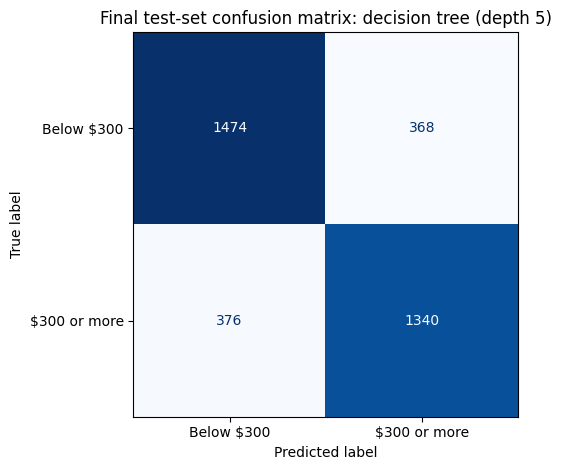

,accommodates,bedrooms,bathrooms,suburb,room_type,Actual high-price class,Predicted high-price class
13055,6,2.0,2.5,Blacktown,Entire home/apt,0,0
14578,8,3.0,2.0,Penrith,Entire home/apt,0,1
18675,2,1.0,1.0,Burwood,Private room,0,0
12909,2,—,1.0,Fairfield,Private room,0,0
4335,3,1.0,1.0,Sydney,Entire home/apt,1,1


In [10]:
# Predict classes for the test set using the already-fitted chosen pipeline.
# This applies its learned preprocessing without refitting it on test data.
test_predictions = best_model.predict(X_test)

# Predict using the baseline, which always selects the most common training class.
baseline_test_predictions = baseline.predict(X_test)

# Compare both models against the true test labels.
# Accuracy weights each listing equally; balanced accuracy weights each class equally.
# Use model names as row labels and round the scores to three decimal places.
display(pd.DataFrame([
    {'Model': name, 'Test accuracy': accuracy_score(y_test, predictions),
     'Test balanced accuracy': balanced_accuracy_score(y_test, predictions)}
    for name, predictions in [('Majority baseline', baseline_test_predictions),
                              (f'Decision tree (depth {best_depth})', test_predictions)]
]).set_index('Model').round(3))

# Plot the chosen model's confusion matrix, with classes ordered as 0 then 1.
# Rows show actual classes; columns show predicted classes.
# Diagonal cells count correct predictions; off-diagonal cells count errors.
# Use blue shading to indicate counts and omit the colour scale bar.
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=['Below $300', '$300 or more'], cmap='Blues', colorbar=False
)

# Add a title, adjust spacing to prevent clipped labels, and display the plot.
#plt.title('Final test set: chosen model')
plt.title(f'Final test-set confusion matrix: decision tree (depth {best_depth})')
plt.tight_layout()
plt.show()

# Copy the first five test listings to show individual prediction examples
# without modifying X_test.
examples = X_test.head().copy()

# Add actual labels, aligned to the examples by their row indexes.
examples['Actual high-price class'] = y_test.head()

# Add predictions for those same rows, using their order in X_test.
examples['Predicted high-price class'] = test_predictions[:len(examples)]

# Display the input features alongside actual and predicted classes.
#display(examples)

def highlight_prediction(row):
    # NOT LaTeX compatible
    matches = row['Actual high-price class'] == row['Predicted high-price class']
    colour = 'green' if matches else 'red'
    return [
        f'color: {colour}; font-weight: bold;'
        if column == 'Predicted high-price class' else ''
        for column in row.index
    ]

'''
#display(examples.style.apply(highlight_prediction, axis=1))
display(
    style_latex_table(
        examples.style.apply(highlight_prediction, axis=1)
    )
)'''

def highlight_prediction_latex(row):
    # LaTeX compatible
    matches = row['Actual high-price class'] == row['Predicted high-price class']
    colour = 'green' if matches else 'red'
    return [
        f'color:{{{colour}}}; bfseries:;'
        if column == 'Predicted high-price class' else ''
        for column in row.index
    ]

latex_table = style_latex_table(
    examples.style
    .format(precision=1, na_rep="—", escape="latex")
    .apply(highlight_prediction_latex, axis=1)
).to_latex()

display({
    "text/html": examples.style
        .format(precision=1, na_rep="—")
        .apply(highlight_prediction, axis=1)
        .to_html(),

    "text/latex": (
        r"\begin{adjustbox}{max width=\linewidth}" "\n"
        + latex_table
        + "\n" r"\end{adjustbox}"
    ),
}, raw=True)

## Recap and questions for students

1. **Clean fixed errors**, but do not fill missing target prices with guesses.
2. **Split rows, not columns.** Stratification preserves the label mix; the three sets have no shared listings.
3. **Learn preprocessing on training only.** A pipeline carries those same rules into validation, test and future predictions.
4. **Train to learn; validate to choose; test to report.** A correlation plot alone cannot measure prediction performance.
5. **Cross-validation rotates internal validation folds.** Relearn the entire pipeline in every round; keep the final test set outside all folds.

**Discuss:** Why is the second `test_size` 0.50 rather than 0.20? Why must price not appear in `X`? Why is a large training score not enough? What does balanced accuracy reveal that ordinary accuracy can hide? In 5-fold CV, how often is each training listing held out? Why must we learn new medians in every fold? Does CV use our final test set?

**Limitations:** This random split evaluates other listings from the same snapshot, not future market prices. Different listings may share a host; a host-grouped split would be needed to evaluate unseen hosts. Stratification does not fix those dependencies or distribution changes. The $300 cutoff is a teaching choice, not a business recommendation; classification scores do not tell us the dollar error in a price estimate.

**Optional classroom experiment:** Before treating any score as final, rerun the lesson with `stratify` removed from both split calls and compare class percentages. With this large dataset, random splitting may already look similar; stratification guarantees a much closer mix. Do not use repeated test results to pick a preferred random seed or model.

## Recap and questions for students

### 1. Clean fixed errors, but do not guess missing target prices

Cleaning makes the data consistent enough to use. In this notebook, fixed cleaning rules include:

- Removing repeated listing IDs.
- Removing leading and trailing whitespace from categorical values.
- Converting invalid numerical text into missing values.
- Marking impossible values, such as negative bedroom counts, as missing.

These rules do not estimate statistics from the dataset. For example, deciding that a negative bedroom count is invalid does not require calculating an average or studying the test set. Such fixed rules can be applied before splitting.

However, **missing input features and missing target information require different treatment**.

An input feature, such as the number of bedrooms, helps the model make a prediction. If it is missing, we can fill it using a value learned from training data, such as the training median.

The price determines the correct answer:

- **Class 0:** price below \$300.
- **Class 1:** price of \$300 or more.

If price is missing or invalid, we do not know the correct class. Filling that price with a guess would create a guessed target label, which could mislead both training and evaluation. We therefore remove those listings from this supervised learning exercise.

**Question:** Why is filling a missing bedroom count different from filling a missing price?

### 2. Split rows, not columns

Each row represents a listing, while each input column represents a feature describing that listing.

We divide the listings into three groups:

| Dataset | Proportion | Purpose |
|---|---:|---|
| Training | 60% | Learn preprocessing values and model rules |
| Validation | 20% | Compare candidates and choose a model |
| Test | 20% | Evaluate the selected model |

All three groups contain the **same input columns**, but different rows. A model trained using bedrooms, bathrooms and room type needs those same kinds of inputs when predicting other listings.

The split happens in two steps:

1. Reserve 60% for training and hold out 40%.
2. Divide the held-out 40% equally into validation and test sets.

**Stratification preserves approximately the same class proportions in each group.** If the full dataset contains 70% class 0 and 30% class 1, each split should have approximately that mix. Stratification does not force a 50/50 balance.

The second split uses the labels belonging to the held-out rows because those are the rows being divided.

Removing duplicate listing IDs before splitting helps prevent the same listing from appearing in multiple sets. The index assertions then check that the sets do not overlap and together cover the original rows.

**Question:** Why could evaluating on a listing already seen during training make the model look better than it really is?

### 3. Learn preprocessing on training data only

Some preprocessing rules require learning values from data. Our pipeline learns:

- The median of each numerical column.
- The most frequent value of each categorical column.
- The categories used to create one-hot encoded columns.

These values must be learned from the training set, rather than from validation or test data.

For example, if the training median for bedrooms is 2, the pipeline stores 2 as its filling value. It then uses that same value for missing bedrooms in validation, test and future listings—even if those datasets have different medians.

The distinction is between **fitting** and **transforming**:

- `model.fit(X_train, y_train)` learns preprocessing values, transforms the training inputs, and trains the tree.
- `model.predict(X_val)` applies the stored preprocessing values and predicts validation labels.
- `best_model.predict(X_test)` applies the selected pipeline to the test inputs.

Prediction does not recalculate the medians or train a new tree.

The pipeline keeps these steps together, but it does not automatically prevent every mistake. Calling `.fit()` on the full dataset before splitting would still allow information from validation and test data to influence training.

**Question:** If the validation median differs from the training median, which one should fill missing validation values, and why?

### 4. Train to learn; validate to choose; test to report

These three datasets answer different questions.

**Training asks: “What patterns can this model learn?”**

For each candidate depth, `.fit(X_train, y_train)` learns the preprocessing values and the tree's decision rules. A deeper tree can learn more detailed patterns, but it can also fit noise or peculiarities of the training listings.

**Validation asks: “Which candidate should we select?”**

The notebook tries depths 1, 2, 3, 5 and 50. Each fitted candidate predicts the validation labels, and we record its scores.

The selection happens here:

`best_depth = validation_results['Validation balanced accuracy'].idxmax()`

This selects the depth with the highest validation balanced accuracy. The next line retrieves its already-fitted pipeline:

`best_model = models[best_depth]`

Training accuracy and ordinary validation accuracy help us understand the results, but neither determines the winner in this notebook. The selection metric is **validation balanced accuracy**.

If scores tie exactly, `.idxmax()` returns the first occurrence. Because the candidate depths are listed in increasing order, the shallower tree wins the tie.

**Test asks: “How well does the selected model perform on untouched examples?”**

Once the choice is fixed, we evaluate `best_model` on the test set and report its accuracy, balanced accuracy and confusion matrix. We also compare it with the majority-class baseline.

We should not change the model because of its test score and then present another evaluation on that same test set as an untouched assessment. Doing so would turn the test set into another source of model-selection feedback.

A correlation plot answers a different question: it describes associations between variables. It does not compare a fitted model's predictions with correct answers on unseen listings, so it cannot replace predictive evaluation.

**Question:** If depth 50 has the highest training accuracy but depth 3 has the highest validation balanced accuracy, which model does this notebook choose?

### 5. Cross-validation rotates internal validation folds

The notebook also uses five-fold cross-validation within the training set to examine how performance varies across different internal splits.

The training set is divided into five folds. Each round uses four folds for learning and the remaining fold for evaluation:

| Round | Learning folds | Held-out fold |
|---|---|---|
| 1 | B, C, D, E | A |
| 2 | A, C, D, E | B |
| 3 | A, B, D, E | C |
| 4 | A, B, C, E | D |
| 5 | A, B, C, D | E |

Every training row is held out exactly once. These internal held-out folds are separate from the dedicated validation set used earlier to select the depth.

`cross_val_score` creates a fresh copy of the entire pipeline for each round. Each copy learns its medians, category filling values, encodings and tree from that round's four learning folds only.

Preprocessing all training rows before cross-validation would allow each held-out fold to influence those preprocessing values. Keeping preprocessing inside the pipeline avoids this leakage.

Training data overlap **between rounds**, which is expected. For example, rounds 1 and 2 both train on folds C, D and E. This overlap is not itself leakage: within each round, its held-out fold remains excluded from fitting. However, the overlap means that the five scores are not independent measurements.

The mean summarises the fold scores, while their standard deviation describes their spread. Neither the spread nor a high mean guarantees performance on future data.

In this notebook, cross-validation assesses the selected configuration. It does not choose one winning fold, replace the already-fitted `best_model`, or use the final test set.

**Question:** Why must the imputer be fitted again inside each round, even though all five folds come from the training set?

## Questions answered

### 1. Why is the second `test_size` 0.50 rather than 0.20?

The first split reserves **60% for training** and holds out **40%**. The second split operates only on that held-out portion.

To obtain validation and test sets that each contain **20% of the original data**, we divide the held-out 40% in half:

$$
0.40 \times 0.50 = 0.20
$$

Using `test_size=0.20` in the second split would allocate only **8% of the original data** to testing:

$$
0.40 \times 0.20 = 0.08
$$

The resulting proportions would be 60% training, 32% validation and 8% test.

### 2. Why must price not appear in `X`?

The target label is calculated directly from price:

- **Class 0:** price below \$300.
- **Class 1:** price of \$300 or more.

Including price in the input features would give the model the information that directly determines the answer. This is **target leakage**.

The task is to predict the price class from other listing characteristics, such as bedrooms, bathrooms and room type. Therefore, neither `price` nor the derived `high_price` label belongs in `X`.

### 3. Why is a large training score not enough?

The training score measures performance on listings the model has already used to learn its rules.

A complex model can achieve a high training score by fitting noise or memorising details that do not generalise. This is **overfitting**.

Validation performance helps us choose a model that works on listings excluded from fitting. The untouched test set then provides the final evaluation of the selected model.

A high training score combined with a much lower validation score is a warning sign of overfitting.

### 4. What does balanced accuracy reveal that ordinary accuracy can hide?

Ordinary accuracy gives every listing equal weight. A large class can therefore dominate the score, hiding poor performance on a smaller class.

Balanced accuracy gives each class equal weight by averaging their recalls:

$$
\text{Balanced accuracy}
= \frac{\text{Recall}_0 + \text{Recall}_1}{2}
$$

For example, suppose 90% of listings belong to class 0. A model that always predicts class 0 achieves:

- **90% accuracy**, because it correctly predicts the larger class.
- **50% balanced accuracy**, because its recalls are 100% for class 0 and 0% for class 1.

Balanced accuracy exposes the model's failure to identify the smaller class. The confusion matrix shows which class it misses.

### 5. In 5-fold cross-validation, how often is each training listing held out?

Each listing is held out **exactly once** and used for learning in the other **four rounds**.

Every round fits a fresh pipeline using four folds and evaluates it on the remaining fold. Across all five rounds, each training listing receives one prediction from a model fitted without its held-out fold.

### 6. Why must we learn new medians in every fold?

Each round's held-out fold represents unseen data for that round. Its values must not influence the preprocessing learned by the model.

Calculating medians once from the entire training set before cross-validation would allow the held-out rows to influence their own preprocessing. This would introduce leakage within cross-validation.

Instead, each round learns medians from its **four learning folds only**, then applies those stored medians to its held-out fold.

The same principle applies to categorical filling values and one-hot encoding categories. Keeping preprocessing inside the pipeline ensures that these steps are fitted again for each round.

### 7. Does cross-validation use our final test set?

**No.** In this notebook, cross-validation operates only on `X_train` and `y_train`.

Its internal held-out folds come from the training set. They are separate from both the dedicated validation set used to choose the depth and the final test set.

The final test set stays outside cross-validation and model selection. It is used afterward to report the selected model's performance on untouched listings.